# Model selection for the 2026 ACIC Data Challenge

**Yuekai Sun · Curated track · Team submission 0002_03**

Across 18 randomized datasets, our team estimated four active-versus-control contrasts and recommended an active treatment for each person.
I worked on this submission with Jin-Hong Du.
This notebook walks through our model selection and estimation pipeline.

Run from the repository root.
Dataset 1 illustrates a fresh fit with a reduced compute budget.
The final sections read the recorded learner sets and evaluate the frozen submission against organizer-released contrasts.
The exact historical environment and frozen-output generator remain unverified.

In [1]:
# https://github.com/YuekaiSun/acic-2026-model-selection
from collections import defaultdict
from dataclasses import dataclass
from functools import partial
from pathlib import Path
from typing import Callable
from zipfile import ZipFile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from econml.dr import DRLearner
from econml.metalearners import SLearner, TLearner, XLearner
from lightgbm import LGBMRegressor
from scipy.special import softmax
from scipy.stats import norm
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.cluster import AgglomerativeClustering
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

DATA = Path("data")
ACTIVE_ARMS = np.array(list("bcde"))
SEED = 42

# LightGBM and EconML trigger these two scikit-learn API warnings in the pinned environment.
warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMRegressor")
warnings.filterwarnings("ignore", message="'force_all_finite' was renamed to 'ensure_all_finite'")

## Encode trial data

Encode the five arms as 0–4, with one active-arm indicator per contrast when treatment enters a pooled model.
Use reference-category indicators for categorical covariates x1–x6, retain binary covariates x7–x23, and standardize x24–x37.
For each of x38–x40, keep a nonzero indicator and standardize the positive values, with zero in the second column when the original value is zero.
Preprocessing uses the full observed sample before fold fitting.

In [2]:
def load_trial(dataset):
    with ZipFile(DATA / "curated_data.zip") as archive:
        with archive.open(f"data_{dataset}.csv") as source:
            return pd.read_csv(source)

def encode_covariates(features):
    for col in ["x38", "x39", "x40"]:
        x = features.pop(col)
        nonzero = x[x != 0]
        features[col + "_indicator"] = x.ne(0).astype(int)
        features[col + "_value"] = 0.0
        features.loc[nonzero.index, col + "_value"] = (nonzero - nonzero.mean()) / nonzero.std()
    for col in [f"x{i}" for i in range(1, 7)]:
        category = features.pop(col)
        indicators = pd.get_dummies(category, prefix=col, drop_first=True, dtype=int)
        features = features.join(indicators)
    continuous = [f"x{i}" for i in range(24, 38)]
    features[continuous] = StandardScaler().fit_transform(features[continuous])
    return features


def model_inputs(trial):
    arm = pd.Categorical(trial.z, categories=list("abcde")).codes.astype(np.int32)
    features = encode_covariates(trial.drop(columns=["ID", "z", "y"]))
    return features.to_numpy(dtype=float), trial.y.to_numpy(dtype=float), arm


def treatment_design(X, arm):
    indicators = arm[:, None] == np.arange(1, 5)
    return np.column_stack([X, indicators])


trial = load_trial(1)
X, y, z = model_inputs(trial)
print(f"Dataset 1: {len(trial):,} people, {X.shape[1]} covariates")
print(trial.z.value_counts().sort_index().to_string())

Dataset 1: 1,000 people, 57 covariates
z
a    164
b    204
c    127
d    276
e    229


## Screen outcome regressions

We grouped linear and tree-based outcome models by similarity of their held-out predictions and selected representatives using cross-validated outcome prediction error.
We retained up to two outcome regressions per cluster and used the best model in each cluster as a candidate nuisance regression for the doubly robust learners.

In [3]:
class AdaptiveLasso(RegressorMixin, BaseEstimator):
    """Ridge-weighted feature scaling retained from the submission code."""

    def __init__(self, alpha=1.0, gamma=1.0, ridge_alpha=1.0):
        self.alpha = alpha
        self.gamma = gamma
        self.ridge_alpha = ridge_alpha

    def fit(self, X, y):
        ridge = Ridge(alpha=self.ridge_alpha)
        ridge.fit(X, y)
        coefs = np.abs(ridge.coef_)
        self.weights_ = 1.0 / np.maximum(coefs, 1e-06) ** self.gamma
        X_w = X * self.weights_
        self.lasso_ = Lasso(alpha=self.alpha, max_iter=10000)
        self.lasso_.fit(X_w, y)
        return self

    def predict(self, X):
        X_w = X * self.weights_
        return self.lasso_.predict(X_w)


def outcome_model_pool():
    forest = partial(RandomForestRegressor, n_estimators=200, min_samples_leaf=5,
                     max_features="sqrt", random_state=SEED, n_jobs=-1)
    xgb = partial(XGBRegressor, n_estimators=150, learning_rate=0.05, max_depth=4,
                  subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbosity=0)
    lgb = partial(LGBMRegressor, n_estimators=150, learning_rate=0.05, max_depth=5,
                  subsample=0.8, random_state=SEED, n_jobs=-1, verbosity=-1)
    return {
        "Ridge_0.1": partial(Ridge, alpha=0.1),
        "Ridge_1": partial(Ridge, alpha=1),
        "Ridge_10": partial(Ridge, alpha=10),
        "Lasso": partial(Lasso, alpha=0.01, max_iter=10000),
        "AdaLasso": partial(AdaptiveLasso, alpha=0.01),
        "RF": forest,
        "XGB": xgb,
        "XGB_shallow": partial(xgb, max_depth=2, n_estimators=200),
        "XGB_deep": partial(xgb, max_depth=6, n_estimators=200, learning_rate=0.03),
        "LGB": lgb,
        "LGB_shallow": partial(lgb, max_depth=3, n_estimators=200),
        "LGB_deep": partial(lgb, max_depth=7, n_estimators=200, learning_rate=0.03),
    }

In [4]:
# Compare outcome regressions on identical held-out folds.
def screen_models(features, outcome, arm, models):
    design = treatment_design(features, arm)
    split = StratifiedKFold(5, shuffle=True, random_state=SEED)
    folds = list(split.split(design, arm))
    held_out, mse = {}, {}
    for name, make_model in models.items():
        prediction = cross_val_predict(make_model(), design, outcome, cv=folds)
        held_out[name] = prediction
        mse[name] = np.mean((outcome - prediction) ** 2)

    names = list(models)
    correlation = np.corrcoef([held_out[name] for name in names])
    distance = np.clip(1 - correlation, 0, 2)
    groups = AgglomerativeClustering(
        n_clusters=3, metric="precomputed", linkage="average"
    ).fit_predict(distance)
    final, nuisance, screening = {}, {}, []
    for cluster in np.unique(groups):
        members = [name for name, group in zip(names, groups) if group == cluster]
        ranked = sorted(members, key=mse.get)
        kept = ranked[:2]
        final.update({name: models[name] for name in kept})
        best = ranked[0]
        nuisance[best] = models[best]
        screening.append((len(members), ", ".join(kept), best))
    summary = pd.DataFrame(screening, columns=["Screened", "Final regressions", "DR nuisance"])
    return final, nuisance, summary


pool = outcome_model_pool()
final, nuisance, screening = screen_models(X, y, z, pool)
print(screening.to_string(index=False))

 Screened        Final regressions DR nuisance
        6 XGB_shallow, LGB_shallow XGB_shallow
        5          Lasso, Ridge_10       Lasso
        1                       RF          RF


## Construct the candidate library
S-learners pool treatment arms; T-learners fit each arm separately. X-learners impute contrasts. Doubly robust learners cross each final model with each nuisance regression. Five final and three nuisance models give 15 DR pairs, 40% fewer than a five-by-five grid.

In [5]:
@dataclass
class Candidate:
    name: str
    build: Callable

def make_dr(nuisance, final):
    return DRLearner(model_regression=nuisance(), model_final=final(),
                     model_propensity=DummyClassifier(strategy="prior"), cv=8, random_state=SEED)

def candidate_grid(final, nuisance):
    candidates = []
    for name, regression in final.items():
        for label, learner, argument in [
            ("S", SLearner, "overall_model"), ("T", TLearner, "models"), ("X", XLearner, "models")
        ]:
            def build(learner=learner, argument=argument, regression=regression):
                return learner(**{argument: regression()})
            candidates.append(Candidate(f"{label}({name})", build))
        for other_name, other in nuisance.items():
            candidates.append(Candidate(f"DR({other_name}→{name})", partial(make_dr, other, regression)))
    return candidates

candidates = candidate_grid(final, nuisance)
print(f"{len(final)} final models, {len(nuisance)} nuisance models, {len(candidates)} candidates")

5 final models, 3 nuisance models, 30 candidates


## Generate local trials

Fit a pooled XGBoost creator with 250 trees, depth 6, learning rate 0.03 and subsampling fraction 0.9 to the observed covariates, treatment and outcome.
Keep the covariates fixed, redraw assignments independently using the observed treatment proportions, and add in-sample residuals resampled within arms with independent random signs.
The creator's active-minus-control conditional means supply the known contrasts for these local simulations.

In [6]:
def fit_creator(X, y, arm):
    model = XGBRegressor(n_estimators=250, learning_rate=0.03, max_depth=6,
                         subsample=0.9, random_state=SEED, n_jobs=-1, verbosity=0)
    design = treatment_design(X, arm)
    model.fit(design, y)
    means = np.column_stack([
        model.predict(treatment_design(X, np.full(len(y), treatment))) for treatment in range(5)
    ])
    residual = y - model.predict(design)
    residuals = [residual[arm == treatment] for treatment in range(5)]
    proportions = np.bincount(arm, minlength=5) / len(arm)
    return means, residuals, proportions

def generate_simulated_data(X, creator, seed):
    means, residuals, proportions = creator
    rng = np.random.RandomState(seed)
    arm = rng.choice(5, size=len(X), p=proportions)
    outcome = means[np.arange(len(X)), arm].astype(float)
    for treatment, pool in enumerate(residuals):
        mask = arm == treatment
        noise = rng.choice(pool, size=mask.sum(), replace=True)
        outcome[mask] += noise * rng.choice([-1, 1], size=mask.sum())
    effects = means[:, 1:] - means[:, [0]]
    return X, outcome, arm, effects

## Score held-out effects and treatment choices
Squared effect error measures error in all four contrasts. Regret measures the expected outcome lost by selecting a lower-performing active arm. Each simulation contributes five held-out fold scores per candidate.

In [7]:
def fit_effects(candidate, X_train, y_train, arm_train, X_test):
    learner = candidate.build()
    learner.fit(y_train, arm_train, X=X_train)
    return np.column_stack([
        learner.effect(X_test, T0=0, T1=t).ravel() for t in range(1, 5)
    ])

def active_arm_regret(predicted, truth):
    chosen = predicted.argmax(axis=1)
    return (truth.max(axis=1) - truth[np.arange(len(truth)), chosen]).mean()

def evaluate_candidates_on_simulation(X, y, arm, truth, candidates, seed):
    errors, regrets = defaultdict(list), defaultdict(list)
    folds = StratifiedKFold(5, shuffle=True, random_state=seed)
    for train, test in folds.split(X, arm):
        for candidate in candidates:
            estimate = fit_effects(candidate, X[train], y[train], arm[train], X[test])
            errors[candidate.name].append(np.mean((estimate - truth[test]) ** 2))
            regrets[candidate.name].append(active_arm_regret(estimate, truth[test]))
    return errors, regrets

In [8]:
def collect_losses(features, outcome, arm, candidates, dataset_id, repeats=15):
    creator = fit_creator(features, outcome, arm)
    errors, regrets = defaultdict(list), defaultdict(list)
    for repeat in range(repeats):
        trial = generate_simulated_data(features, creator, seed=1000 * repeat + dataset_id)
        fold_error, fold_regret = evaluate_candidates_on_simulation(
            *trial, candidates, seed=SEED + repeat)
        for name in fold_error:
            errors[name].extend(fold_error[name])
            regrets[name].extend(fold_regret[name])
    return errors, regrets

## Select and cross-fit separate ensembles

Apply the submission's Winners with Confidence rule at level 0.05 separately to squared effect error and active-arm regret.
Compare each candidate to a weighted average of the others, estimating the weights on the other loss folds.
Then refit the retained learners on four of five observed-data folds and average their held-out effect predictions with equal weights.
The effect ensemble supplies the contrasts and the regret ensemble supplies the recommendations.
Screening and creator fitting use the full observed sample before these fits.

In [9]:
def select_models(records):
    names = sorted(records)
    loss = np.column_stack([records[name] for name in names])
    n = len(loss)
    scale = np.sqrt(2 * np.log(len(names)) / n)
    fold_id = np.arange(n) % 5
    selected = []
    for j, name in enumerate(names):
        gap = np.empty(n)
        for fold in range(5):
            test = fold_id == fold
            log_weights = -scale * loss[~test].mean(axis=0)
            log_weights[j] = -np.inf
            rival_loss = loss[test] @ softmax(log_weights)
            gap[test] = loss[test, j] - rival_loss
        spread = max(gap.std(ddof=1), 1e-12)
        statistic = np.sqrt(n) * gap.mean() / spread
        if statistic < norm.ppf(0.95):
            selected.append(name)
    if selected:
        return selected
    return [names[loss.mean(axis=0).argmin()]]

In [10]:
def crossfit_ensemble(X, y, arm, selected):
    effects = np.empty((len(y), 4))
    folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
    for train, test in folds.split(X, arm):
        predictions = [
            fit_effects(member, X[train], y[train], arm[train], X[test]) for member in selected
        ]
        effects[test] = np.mean(predictions, axis=0)
    return effects

## Out-of-bag bootstrap and submission files

Keep both selections fixed. To form percentile intervals, refit the effect ensemble on each bootstrap sample and predict only observations omitted from that draw.
Average those predictions within each draw for the sample and x12 subgroup intervals.
The PATE point estimate is the cross-fitted sample average.
As in the frozen submission and restored implementation, center the PATE interval there and multiply the sCATE bootstrap half-width by $\sqrt{10/9}$.

In [11]:
def bootstrap_effects(X, y, arm, selected, draws):
    rng = np.random.RandomState(SEED)
    n = len(y)
    samples = np.full((draws, n, 4), np.nan)
    for draw in range(draws):
        rows = rng.choice(n, size=n, replace=True)
        out_of_bag = np.ones(n, dtype=bool)
        out_of_bag[rows] = False
        predictions = [
            fit_effects(member, X[rows], y[rows], arm[rows], X[out_of_bag])
            for member in selected
        ]
        samples[draw, out_of_bag] = np.mean(predictions, axis=0)
    return samples

In [12]:
def effect_table(index, point, draws):
    lower, upper = np.nanpercentile(draws, [2.5, 97.5], axis=0)
    return index.assign(Estimate=point.ravel(), L95=lower.ravel(), U95=upper.ravel())

def write_submission(dataset, trial, effects, policy, samples, directory):
    arms = pd.DataFrame({"z": ACTIVE_ARMS})
    units = pd.DataFrame({"ID": trial.ID}).merge(arms, how="cross")
    individual = effect_table(units, effects, samples)
    sample = effect_table(arms, effects.mean(axis=0), np.nanmean(samples, axis=1))
    # Use the width adjustment observed in the frozen submission.
    half_width = (sample.U95 - sample.L95) * np.sqrt(10 / 9) / 2
    population = sample.assign(L95=sample.Estimate - half_width, U95=sample.Estimate + half_width)
    subgroup, subgroup_choices = [], []
    for value in (0, 1):
        rows = trial.x12.to_numpy() == value
        subgroup.append(effect_table(arms.assign(x=value), effects[rows].mean(axis=0),
                                     np.nanmean(samples[:, rows], axis=1)))
        best = ACTIVE_ARMS[policy[rows].mean(axis=0).argmax()]
        subgroup_choices.append({"x": value, "best_z": best.upper()})
    best = ACTIVE_ARMS[policy.mean(axis=0).argmax()]
    tables = {
        "iCATE": individual.sort_values(["z", "ID"]),
        "sCATE": sample,
        "subCATE": pd.concat(subgroup).sort_values(["z", "x"]),
        "PATE": population,
        "BEST_iCATE": pd.DataFrame({"ID": trial.ID, "best_z": ACTIVE_ARMS[policy.argmax(axis=1)]}),
        "BEST_sCATE": pd.DataFrame({"best_z": [best]}),
        "BEST_subCATE": pd.DataFrame(subgroup_choices),
        "BEST_PATE": pd.DataFrame({"best_z": [best.upper()]}),
    }
    directory.mkdir(parents=True, exist_ok=True)
    paths = []
    for target, table in tables.items():
        path = directory / f"{target}_{dataset:04d}_{directory.name}.csv"
        table.to_csv(path, index=False)
        paths.append(path)
    return paths

In [13]:
def fit_submission(dataset, X, y, arm, trial, candidates, repeats, draws, directory):
    errors, regrets = collect_losses(X, y, arm, candidates, dataset, repeats)
    effect_names = select_models(errors)
    policy_names = select_models(regrets)
    effect_members = [c for c in candidates if c.name in effect_names]
    effects = crossfit_ensemble(X, y, arm, effect_members)
    policy = effects
    if set(policy_names) != set(effect_names):
        policy_members = [c for c in candidates if c.name in policy_names]
        policy = crossfit_ensemble(X, y, arm, policy_members)
    samples = bootstrap_effects(X, y, arm, effect_members, draws)
    counts = np.isfinite(samples[:, :, 0]).sum(axis=0)
    print(f"Selected learners: {len(effect_members)} for effect error, "
          f"{len(policy_names)} for regret")
    print(f"Out-of-bag draws per person: {counts.min()}–{counts.max()}")
    return write_submission(dataset, trial, effects, policy, samples, directory)

def refit_dataset(dataset):
    trial = load_trial(dataset)
    X, y, arm = model_inputs(trial)
    final, nuisance, _ = screen_models(X, y, arm, outcome_model_pool())
    return fit_submission(dataset, X, y, arm, trial, candidate_grid(final, nuisance),
                          repeats=15, draws=200, directory=Path("refits/refit_full"))

**Small refit, dataset 1.** Run all stages using five candidates spanning the S-, T-, X- and doubly robust families, one plasmode and 30 out-of-bag bootstrap draws.
These intervals illustrate the export.
For a paper-scale refit, `refit_dataset` uses the full screened library, 15 plasmodes, five-fold predictions and 200 out-of-bag bootstrap draws for each dataset.

    for dataset in range(1, 19):
        refit_dataset(dataset)

In [14]:
example_names = {"S(Lasso)", "S(Ridge_10)", "T(Lasso)", "X(Lasso)", "DR(Lasso→Ridge_10)"}
example = [c for c in candidates if c.name in example_names]
paths = fit_submission(1, X, y, z, trial, example, repeats=1, draws=30,
                       directory=Path("refits/refit_example"))
for path in paths:
    print(Path(path).name, pd.read_csv(path).shape)

Selected learners: 2 for effect error, 2 for regret
Out-of-bag draws per person: 2–21
iCATE_0001_refit_example.csv (4000, 5)
sCATE_0001_refit_example.csv (4, 4)
subCATE_0001_refit_example.csv (8, 5)
PATE_0001_refit_example.csv (4, 4)
BEST_iCATE_0001_refit_example.csv (1000, 2)
BEST_sCATE_0001_refit_example.csv (1, 1)
BEST_subCATE_0001_refit_example.csv (2, 2)
BEST_PATE_0001_refit_example.csv (1, 1)


## Recorded model selection across all 18 datasets

Read the ensembles retained in the competition run, with 15 simulations and five folds per dataset.
The ranking table shows the first two learners under each criterion for dataset 1.

The figure shows the 12 learners most often retained across the two criteria.
Each dot counts the datasets in which the learner entered the corresponding ensemble.
The screened candidate pool can vary by dataset.

In [15]:
members = pd.read_csv(DATA / "members.csv")
sizes = members.groupby(["dataset", "loss"]).learner.nunique().unstack()
rankings = pd.read_csv(DATA / "rankings.csv")
first_two = rankings.query("dataset == 1 and rank <= 2")
print(first_two[["loss", "rank", "learner", "mean_loss"]].to_string(index=False))
print(f"Recorded dataset 1 ensembles: {sizes.loc[1, 'PEHE']} for error, {sizes.loc[1, 'Regret']} for regret")

  loss  rank        learner  mean_loss
  pehe     1 S(LGB_shallow)   0.116900
  pehe     2       S(Lasso)   0.120200
regret     1    S(Ridge_10)   0.037523
regret     2       S(Lasso)   0.037523
Recorded dataset 1 ensembles: 12 for error, 11 for regret


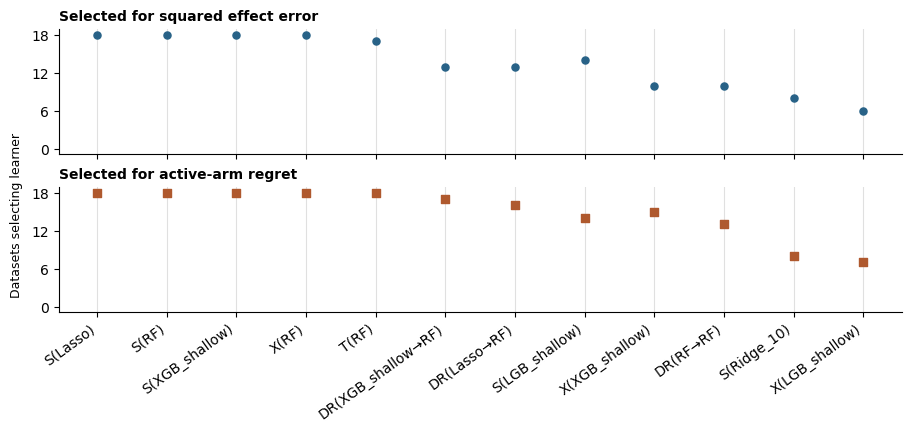

In [16]:
# Count distinct datasets selecting each learner under each criterion.
counts = members.groupby(["learner", "loss"]).dataset.nunique().unstack(fill_value=0)
most_selected = counts.sum(axis=1).nlargest(12).index
shown = counts.loc[most_selected, ["PEHE", "Regret"]]

x = np.arange(len(shown))
fig, axes = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(9, 4.2),
                         layout="constrained")
for ax, loss, title, color, marker in [
    (axes[0], "PEHE", "Selected for squared effect error", "#286287", "o"),
    (axes[1], "Regret", "Selected for active-arm regret", "#AF592E", "s"),
]:
    ax.scatter(x, shown[loss], color=color, marker=marker, s=26, zorder=3)
    ax.set_title(title, loc="left", weight="semibold", fontsize=10)
    ax.grid(axis="x", color="0.88")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set(yticks=[0, 6, 12, 18], ylim=(-0.8, 19))
axes[1].set_xticks(x, shown.index, rotation=36, ha="right")
fig.supylabel("Datasets selecting learner", fontsize=9)
plt.show()

## Evaluate the frozen submission against released truth
Join predictions to the released effects by dataset, unit and treatment. For policy regret, score the actual recommendations from the regret ensemble. Compute each metric separately within dataset and report the average across all 18.

In [17]:
unit = ["dataset", "unit"]
keys = unit + ["arm"]
predictions = pd.read_csv(DATA / "submission.csv.gz")
truth = pd.read_csv(DATA / "released.csv.gz")
choices = pd.read_csv(DATA / "recommendations.csv.gz")

scored = predictions.merge(truth, on=keys, how="outer", validate="one_to_one")
assert scored[["estimate", "truth"]].notna().all().all()
squared_error = (scored.estimate - scored.truth) ** 2
rmse = squared_error.groupby(scored.dataset).mean().pow(0.5)

best = truth.groupby(unit, as_index=False).agg(best=("truth", "max"))
selected = choices.merge(truth.rename(columns={"arm": "choice"}), on=unit + ["choice"],
                         how="left", validate="one_to_one")
selected = best.merge(selected, on=unit, how="outer", validate="one_to_one")
assert selected[["best", "truth"]].notna().all().all()
regret = (selected.best - selected.truth).groupby(selected.dataset).mean()

print(f"Mean dataset conditional-effect RMSE: {rmse.mean():.3f}")
print(f"Mean dataset active-arm regret: {regret.mean():.3f}")

Mean dataset conditional-effect RMSE: 0.618
Mean dataset active-arm regret: 0.057


Mean dataset conditional-effect RMSE was **0.618**.
Mean active-arm regret was **0.057 outcome units** relative to the best active arm.
Both averages give equal weight to the 18 datasets and evaluate the saved 0002_03 predictions and recommendations.

**Sources.** Perrett, Deshpande and Hill, *More Treatments More Problems: Designing the 2026 American Causal Inference Conference Data Challenge*.
Zhang, Lee and Lei, *Winners with Confidence* (2024).